In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

# Core PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F

# Dataset and DataLoader
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Image processing
from PIL import Image
import os
import numpy as np
import matplotlib.pyplot as plt

# Dataset splitting and evaluation
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Device selection
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

# Reproducibility
torch.manual_seed(0)
np.random.seed(0)


Using device: cpu


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

paths = [
    "/content/drive/MyDrive",
    "/content/drive/MyDrive/Rose_Marigold_Dataset",
    "/content/drive/MyDrive/Rose_Marigold_Dataset/Perfect Data Set"
]

for path in paths:
    print("\nPath:", path)
    print("Exists:", os.path.exists(path))

    if os.path.isdir(path):
        print("Folders:", os.listdir(path)[:30])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Path: /content/drive/MyDrive
Exists: True
Folders: ['Colab Notebooks', '10700_1_202010211229049461_cfa78b70-b60d-4fa8-93e8-dc3d441810e1.pdf', 'Bu wedding', 'DCIM', 'Music', 'Pdf', 'Photo', 'Unmesh', 'Bu wedding (1)', 'Pdf (1)', 'Photo (1)', 'Unmesh (1)', 'Unmesh (2)', 'Camera', 'pub.pdf', 'IMG-20220618-WA0000.jpg', '20220628_141244.jpg', '123.jpg', 'Backups', 'Databases', 'Media', 'com.whatsapp', 'parves cv docs  (1).pdf', 'parves cv docs .pdf', 'Jearl Walker-Fundamentals of Physics, 10th ed., Halliday.gdoc', 'download', '20230821_161832.jpg', '2000-01-30 02.06.17.jpg', '2000-01-30 02.04.39.jpg', '2000-01-30 02.03.10.jpg']

Path: /content/drive/MyDrive/Rose_Marigold_Dataset
Exists: False

Path: /content/drive/MyDrive/Rose_Marigold_Dataset/Perfect Data Set
Exists: False


In [ ]:

import os

# Google Drive main folder
base_path = "/content/drive/MyDrive"

# Show all folders and files in MyDrive
items = sorted(os.listdir(base_path))

print("Total items in MyDrive:", len(items))
print("\nAll folder and file names:\n")

for item in items:
    full_path = os.path.join(base_path, item)

    if os.path.isdir(full_path):
        print("[FOLDER]", item)
    else:
        print("[FILE]", item)


# Search for dataset-related names
print("\n----- DATASET SEARCH -----")

keywords = ["rose", "marigold", "leaf", "disease"]

for item in items:
    if any(word in item.lower() for word in keywords):
        print("Possible Dataset:", item)


Total items in MyDrive: 247

All folder and file names:

[FILE] 10.jpg
[FILE] 10700_1_202010211229049461_cfa78b70-b60d-4fa8-93e8-dc3d441810e1.pdf
[FILE] 123.jpg
[FILE] 13.jpg
[FILE] 18.jpg
[FILE] 19.jpg
[FILE] 20.jpg
[FILE] 2000-01-30 01.48.39.jpg
[FILE] 2000-01-30 01.49.16.jpg
[FILE] 2000-01-30 01.51.48.jpg
[FILE] 2000-01-30 02.01.29.jpg
[FILE] 2000-01-30 02.02.03.jpg
[FILE] 2000-01-30 02.02.17.jpg
[FILE] 2000-01-30 02.03.10.jpg
[FILE] 2000-01-30 02.04.39.jpg
[FILE] 2000-01-30 02.05.26.jpg
[FILE] 2000-01-30 02.06.17.jpg
[FILE] 20200626_213901.jpg
[FILE] 20200823_225607.jpg
[FILE] 20210305_045034.jpg
[FILE] 20210828_143522.jpg
[FILE] 20210828_143550.jpg
[FILE] 20210828_143614.jpg
[FILE] 20210828_143630.jpg
[FILE] 20210828_143642.jpg
[FILE] 20210828_143701.jpg
[FILE] 20210828_145635.jpg
[FILE] 20210828_145702.jpg
[FILE] 20210828_145719.jpg
[FILE] 20220628_022606.jpg
[FILE] 20220628_022623.jpg
[FILE] 20220628_141244.jpg
[FILE] 20230215_013310.jpg
[FILE] 20230821_161832.jpg
[FILE] 21.jpg


In [ ]:

import os

base_path = "/content/drive/MyDrive"

matches = []

print("Searching for Rose and Marigold Dataset...")

for current_path, folders, files in os.walk(base_path):

    folder_names = {name.lower() for name in folders}

    # Check whether both plant folders exist together
    if "marigold" in folder_names and "rose" in folder_names:

        matches.append(current_path)

print("\nSearch Completed!")

if matches:
    print("\nDataset Found:")

    for path in matches:
        print(path)

else:
    print("\nDataset not found in Google Drive.")


Searching for Rose and Marigold Dataset...

Search Completed!

Dataset not found in Google Drive.


In [ ]:
import os

DATA_ROOT = "/content/drive/MyDrive/Rose_Marigold_Dataset/Perfect Data Set"

print("Dataset Exists:", os.path.exists(DATA_ROOT))

if os.path.exists(DATA_ROOT):

    print("\nDataset Folders:")

    for folder in os.listdir(DATA_ROOT):
        print(folder)

Dataset Exists: True

Dataset Folders:
rose
marigold


In [ ]:

# Required library
import os

# Empty lists
image_paths = []
labels = []

# Supported image formats
image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

# Plant folders
plant_folders = ["marigold", "rose"]

# Collect images
for plant in plant_folders:

    plant_path = os.path.join(DATA_ROOT, plant)

    # Check plant folder
    if not os.path.isdir(plant_path):
        raise FileNotFoundError(f"Folder not found: {plant_path}")

    # Find disease categories
    for class_name in sorted(os.listdir(plant_path)):

        class_path = os.path.join(plant_path, class_name)

        if not os.path.isdir(class_path):
            continue

        # Create unique class label
        label_name = plant + " - " + class_name

        # Collect images
        for root, dirs, files in os.walk(class_path):

            for file in files:

                if file.lower().endswith(image_extensions):

                    image_path = os.path.join(root, file)

                    image_paths.append(image_path)
                    labels.append(label_name)


# Display results
print("Total Images:", len(image_paths))
print("Total Classes:", len(set(labels)))

print("\nClass Names:")

for name in sorted(set(labels)):
    print(name)


Total Images: 3449
Total Classes: 7

Class Names:
marigold - Alternaria Leaf Blight
marigold - Helathy Leaves
marigold - Pest Damaged
rose - Healthy
rose - Pest Damage
rose - Rose Mosaic Virus
rose - botrytis blight


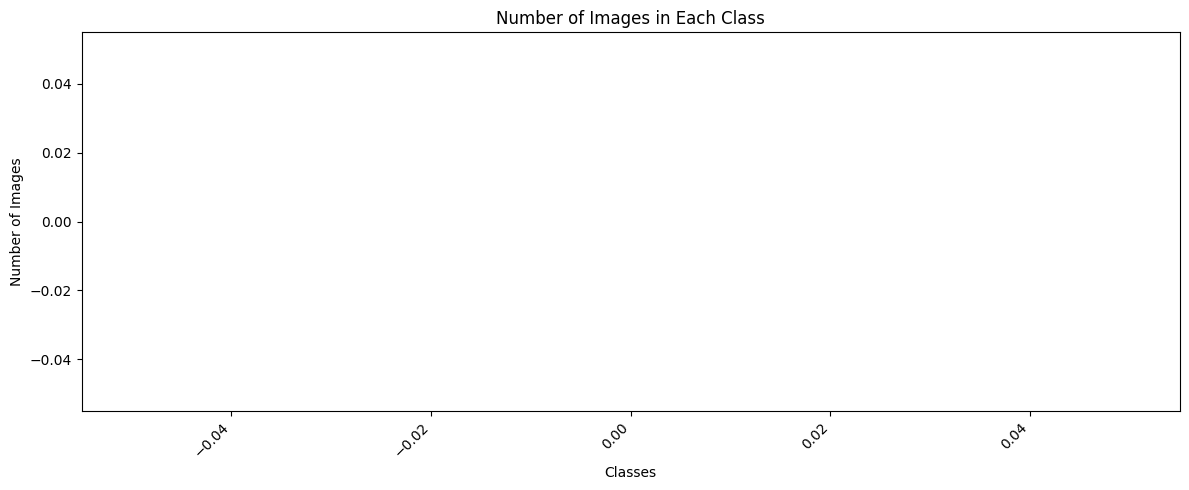

Class Distribution:


In [ ]:

from collections import Counter

class_counts = Counter(labels)

plt.figure(figsize=(12, 5))

plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.title("Number of Images in Each Class")
plt.xlabel("Classes")
plt.ylabel("Number of Images")

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("Class Distribution:")

for class_name, count in sorted(class_counts.items()):
    print(class_name, ":", count)


Image Count Per Class:

marigold - Alternaria Leaf Blight: 338
marigold - Helathy Leaves: 273
marigold - Pest Damaged: 78
rose - Healthy: 1167
rose - Pest Damage: 790
rose - Rose Mosaic Virus: 245
rose - botrytis blight: 558


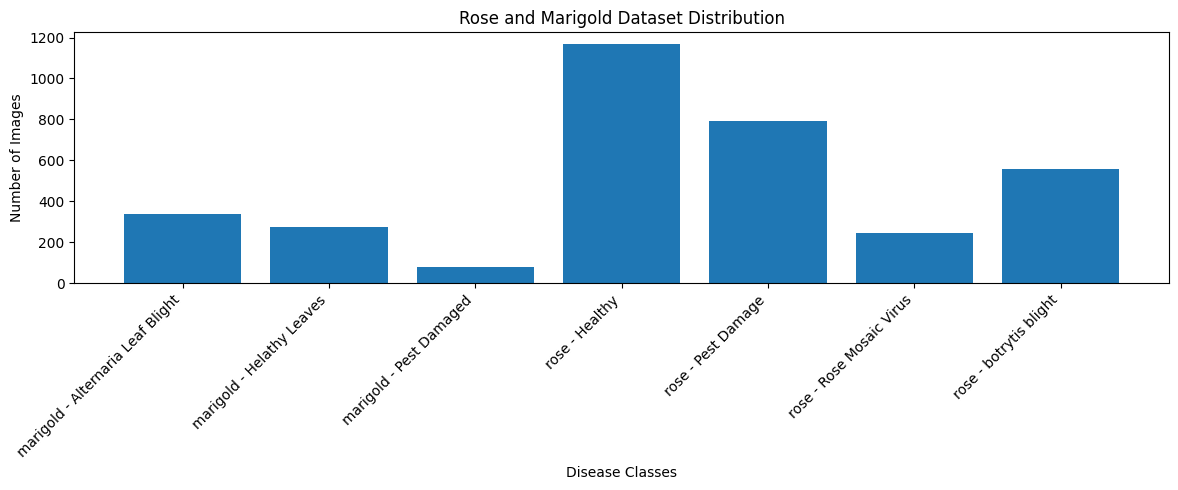

In [ ]:

from collections import Counter
import matplotlib.pyplot as plt

# Count images in each class
class_counts = Counter(labels)

print("Image Count Per Class:\n")

for class_name, count in sorted(class_counts.items()):

    print(f"{class_name}: {count}")


# Create bar chart
plt.figure(figsize=(12, 5))

plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.title("Rose and Marigold Dataset Distribution")

plt.xlabel("Disease Classes")
plt.ylabel("Number of Images")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.show()


In [ ]:

from sklearn.model_selection import train_test_split

# Create class names
class_names = sorted(set(labels))

# Convert class names into numeric labels
class_to_idx = {
    name: idx for idx, name in enumerate(class_names)
}

numeric_labels = [
    class_to_idx[label] for label in labels
]

# Split dataset
train_paths, val_paths, train_labels, val_labels = train_test_split(

    image_paths,
    numeric_labels,

    test_size=0.20,

    random_state=42,

    stratify=numeric_labels
)

# Display results
print("Total Images:", len(image_paths))

print("Training Images:", len(train_paths))

print("Validation Images:", len(val_paths))

print("\nClass Mapping:")

for name, idx in class_to_idx.items():
    print(name, "=", idx)


Total Images: 3449
Training Images: 2759
Validation Images: 690

Class Mapping:
marigold - Alternaria Leaf Blight = 0
marigold - Helathy Leaves = 1
marigold - Pest Damaged = 2
rose - Healthy = 3
rose - Pest Damage = 4
rose - Rose Mosaic Virus = 5
rose - botrytis blight = 6


In [ ]:
class LeafDataset(Dataset):

    def __init__(self, paths, labels, transform=None):

        self.paths = paths
        self.labels = labels
        self.transform = transform


    def __len__(self):

        return len(self.paths)


    def __getitem__(self, index):

        image_path = self.paths[index]

        label = self.labels[index]

        # Open image and convert to RGB
        image = Image.open(image_path).convert("RGB")

        # Apply image transformations
        if self.transform:
            image = self.transform(image)

        return image, label


In [ ]:

IMG_SIZE = 128
BATCH_SIZE = 32

# Training Image Transformation
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor()
])

# Validation Image Transformation
val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

print("Image Transformation Created Successfully!")


Image Transformation Created Successfully!


In [ ]:

# Create Training Dataset
train_ds = LeafDataset(
    train_paths,
    train_labels,
    transform=train_transform
)

# Create Validation Dataset
val_ds = LeafDataset(
    val_paths,
    val_labels,
    transform=val_transform
)

print("Training Dataset:", len(train_ds))
print("Validation Dataset:", len(val_ds))


Training Dataset: 2759
Validation Dataset: 690


In [ ]:

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Training DataLoader Created!")
print("Validation DataLoader Created!")


Training DataLoader Created!
Validation DataLoader Created!


Image Batch Shape: torch.Size([32, 3, 128, 128])
Label Batch Shape: torch.Size([32])

Image Size: 128 x 128
Number of Images in Batch: 32


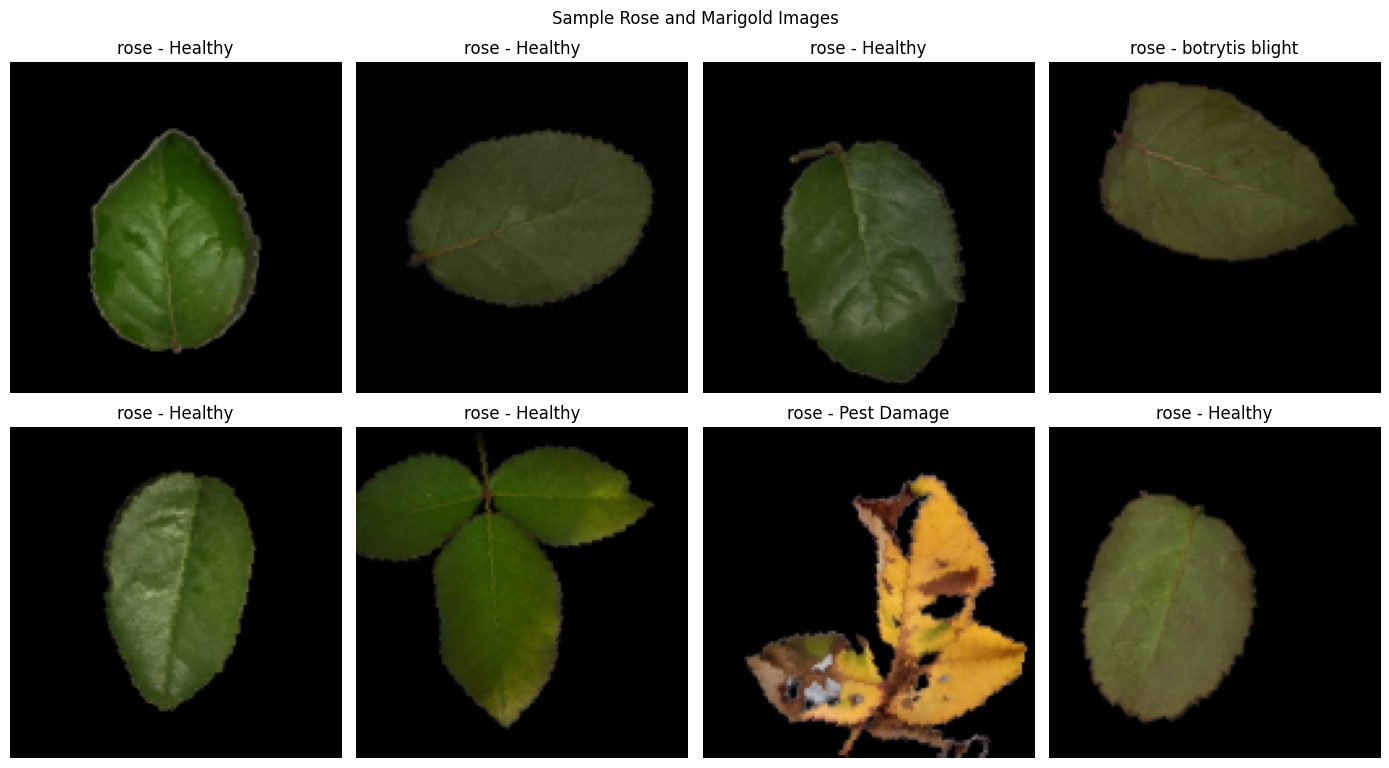

In [ ]:

# Get one batch from training DataLoader
images, targets = next(iter(train_loader))

# Check batch information
print("Image Batch Shape:", images.shape)
print("Label Batch Shape:", targets.shape)

print("\nImage Size:", images.shape[2], "x", images.shape[3])
print("Number of Images in Batch:", images.shape[0])

# Display sample images
plt.figure(figsize=(14, 8))

for i in range(8):

    plt.subplot(2, 4, i + 1)

    # Convert tensor to image format
    img = images[i].permute(1, 2, 0).numpy()

    plt.imshow(img)

    # Show class name
    label_id = targets[i].item()

    plt.title(class_names[label_id])

    plt.axis("off")

plt.suptitle("Sample Rose and Marigold Images")

plt.tight_layout()

plt.show()


In [ ]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")

Device: cuda
GPU: Tesla T4


In [ ]:

IMG_SIZE = 128
BATCH_SIZE = 32

# Basic Transformation
basic_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

# Validation Transformation
val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

# Create Basic Training Dataset
train_ds_basic = LeafDataset(
    train_paths,
    train_labels,
    transform=basic_transform
)

# Create Validation Dataset
val_ds_clean = LeafDataset(
    val_paths,
    val_labels,
    transform=val_transform
)

# Create DataLoaders
train_loader_basic = DataLoader(
    train_ds_basic,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader_clean = DataLoader(
    val_ds_clean,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Basic Training Dataset:", len(train_ds_basic))
print("Validation Dataset:", len(val_ds_clean))
print("DataLoader Created Successfully!")


NameError: name 'train_paths' is not defined

In [ ]:

# Check which important variables exist

check_variables = [
    "train_paths",
    "train_labels",
    "val_paths",
    "val_labels",
    "image_paths",
    "labels",
    "class_to_idx",
    "LeafDataset",
    "transforms"
]

print("Checking Notebook Variables...\n")

for name in check_variables:

    if name in globals():
        print(name, "=> AVAILABLE")
    else:
        print(name, "=> NOT FOUND")


Checking Notebook Variables...

train_paths => NOT FOUND
train_labels => NOT FOUND
val_paths => NOT FOUND
val_labels => NOT FOUND
image_paths => NOT FOUND
labels => NOT FOUND
class_to_idx => NOT FOUND
LeafDataset => AVAILABLE
transforms => AVAILABLE


In [ ]:

# Import required libraries
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

# Define Custom Dataset Class
class LeafDataset(Dataset):

    def __init__(self, paths, labels, transform=None):

        self.paths = paths
        self.labels = labels
        self.transform = transform


    def __len__(self):

        return len(self.paths)


    def __getitem__(self, index):

        image_path = self.paths[index]

        label = self.labels[index]

        # Open image and convert to RGB
        image = Image.open(image_path).convert("RGB")

        # Apply transformation
        if self.transform:
            image = self.transform(image)

        return image, label


print("LeafDataset Class Defined Successfully!")


LeafDataset Class Defined Successfully!


In [ ]:

# Import image transformation library
from torchvision import transforms

# Define image size and batch size
IMG_SIZE = 128
BATCH_SIZE = 32

print("Transforms Imported Successfully!")
print("Image Size:", IMG_SIZE)
print("Batch Size:", BATCH_SIZE)


Transforms Imported Successfully!
Image Size: 128
Batch Size: 32


In [ ]:

# Import PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F

# Import Dataset and DataLoader
from torch.utils.data import Dataset, DataLoader

# Import Image Processing
from PIL import Image
from torchvision import transforms

# Other Libraries
import os
import numpy as np
import matplotlib.pyplot as plt

# Dataset Splitting
from sklearn.model_selection import train_test_split

print("All Libraries Imported Successfully!")


All Libraries Imported Successfully!


In [ ]:

# ==========================================
# REBUILD DATASET PATHS AND LABELS
# ==========================================

import os
from google.colab import drive
from sklearn.model_selection import train_test_split
from collections import Counter

# Step 1: Mount Google Drive
drive.mount('/content/drive')

# Step 2: Dataset main folder
DATASET_PATH = "/content/drive/MyDrive/Rose_Marigold_Dataset/Perfect Data Set"

# Step 3: Check dataset folder
if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(
        f"Dataset folder not found: {DATASET_PATH}"
    )

# Step 4: Collect image paths and class names
image_paths = []
class_names = []

valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

for plant in ['marigold', 'rose']:

    plant_path = os.path.join(DATASET_PATH, plant)

    if not os.path.isdir(plant_path):
        raise FileNotFoundError(f"Missing folder: {plant_path}")

    for current_path, folders, files in os.walk(plant_path):

        for file in files:

            if file.lower().endswith(valid_extensions):

                image_path = os.path.join(current_path, file)

                relative_path = os.path.relpath(
                    image_path, DATASET_PATH
                )

                parts = relative_path.split(os.sep)

                if len(parts) < 3:
                    continue

                class_name = f"{parts[0]} - {parts[1]}"

                image_paths.append(image_path)
                class_names.append(class_name)


# Step 5: Create class mapping
unique_classes = sorted(set(class_names))

class_to_idx = {
    name: idx for idx, name in enumerate(unique_classes)
}

# Step 6: Convert class names into numeric labels
labels = [
    class_to_idx[name] for name in class_names
]

# Step 7: Split dataset into training and validation
train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

# Step 8: Display results
print("\nDataset Preparation Completed!")

print("\nTotal Images:", len(image_paths))
print("Training Images:", len(train_paths))
print("Validation Images:", len(val_paths))
print("Total Classes:", len(class_to_idx))

print("\nClass Mapping:")

for name, idx in class_to_idx.items():
    print(name, "=", idx)

print("\nTraining Class Distribution:")
print(Counter(train_labels))


Mounted at /content/drive

Dataset Preparation Completed!

Total Images: 3449
Training Images: 2759
Validation Images: 690
Total Classes: 7

Class Mapping:
marigold - Alternaria Leaf Blight = 0
marigold - Helathy Leaves = 1
marigold - Pest Damaged = 2
rose - Healthy = 3
rose - Pest Damage = 4
rose - Rose Mosaic Virus = 5
rose - botrytis blight = 6

Training Class Distribution:
Counter({3: 934, 4: 632, 6: 446, 0: 270, 1: 218, 5: 196, 2: 63})


In [ ]:

# ==========================================
# STEP 1: BASIC AND AUGMENTED DATASET
# ==========================================

import torch
from torch.utils.data import DataLoader
from torchvision import transforms

# Image settings
IMG_SIZE = 128
BATCH_SIZE = 32

# --------------------------------
# A. Basic Transformation
# --------------------------------

basic_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

# --------------------------------
# B. Validation Transformation
# --------------------------------

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

# --------------------------------
# C. Augmentation Transformation
# --------------------------------

aug_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor()
])

# --------------------------------
# D. Create Basic Dataset
# --------------------------------

train_ds_basic = LeafDataset(
    train_paths,
    train_labels,
    transform=basic_transform
)

# --------------------------------
# E. Create Augmented Dataset
# --------------------------------

train_ds_aug = LeafDataset(
    train_paths,
    train_labels,
    transform=aug_transform
)

# --------------------------------
# F. Create Validation Dataset
# --------------------------------

val_ds_clean = LeafDataset(
    val_paths,
    val_labels,
    transform=val_transform
)

# --------------------------------
# G. Create DataLoaders
# --------------------------------

train_loader_basic = DataLoader(
    train_ds_basic,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

train_loader_aug = DataLoader(
    train_ds_aug,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader_clean = DataLoader(
    val_ds_clean,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# --------------------------------
# H. Display Results
# --------------------------------

print("Basic Training Dataset:", len(train_ds_basic))
print("Augmented Training Dataset:", len(train_ds_aug))
print("Validation Dataset:", len(val_ds_clean))

print("\nAll DataLoaders Created Successfully!")


Basic Training Dataset: 2759
Augmented Training Dataset: 2759
Validation Dataset: 690

All DataLoaders Created Successfully!


In [ ]:

# Get one batch of images
images, labels_batch = next(iter(train_loader_basic))

print("Image Batch Shape:", images.shape)
print("Label Batch Shape:", labels_batch.shape)

print("Image Height:", images.shape[2])
print("Image Width:", images.shape[3])
print("Number of Channels:", images.shape[1])

print("First 10 Labels:", labels_batch[:10])


Image Batch Shape: torch.Size([32, 3, 128, 128])
Label Batch Shape: torch.Size([32])
Image Height: 128
Image Width: 128
Number of Channels: 3
First 10 Labels: tensor([3, 3, 4, 3, 4, 4, 4, 3, 4, 3])


In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F

# CNN Architecture
class SimpleCNN(nn.Module):

    def __init__(self, num_classes=7, p_dropout=0.0):

        super(SimpleCNN, self).__init__()

        # Convolutional Layers
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)

        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)

        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        # Max Pooling
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Dropout
        self.dropout = nn.Dropout(p_dropout)

        # Fully Connected Layers
        self.fc1 = nn.Linear(64 * 16 * 16, 128)

        self.fc2 = nn.Linear(128, num_classes)


    def forward(self, x):

        # Block 1
        x = self.pool(F.relu(self.conv1(x)))

        # Block 2
        x = self.pool(F.relu(self.conv2(x)))

        # Block 3
        x = self.pool(F.relu(self.conv3(x)))

        # Flatten
        x = torch.flatten(x, 1)

        # Dropout
        x = self.dropout(x)

        # Fully Connected
        x = F.relu(self.fc1(x))

        # Output
        x = self.fc2(x)

        return x


print("SimpleCNN Architecture Defined Successfully!")


SimpleCNN Architecture Defined Successfully!


In [ ]:

# Select device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Create CNN Model
model_basic = SimpleCNN(
    num_classes=len(class_to_idx),
    p_dropout=0.0
).to(device)

print("\nCNN Model Created Successfully!")

# Count parameters
total_params = sum(
    p.numel()
    for p in model_basic.parameters()
    if p.requires_grad
)

print("Trainable Parameters:", total_params)


Using Device: cuda
GPU: Tesla T4

CNN Model Created Successfully!
Trainable Parameters: 2121767


In [ ]:

# Get one image batch
images, labels_batch = next(iter(train_loader_basic))

x = images[:1].to(device)

model_basic.eval()

with torch.no_grad():

    print("Input:", x.shape)

    x = model_basic.conv1(x)
    print("After Conv1:", x.shape)

    x = F.relu(x)
    x = model_basic.pool(x)
    print("After MaxPool1:", x.shape)

    x = model_basic.conv2(x)
    x = F.relu(x)
    x = model_basic.pool(x)
    print("After MaxPool2:", x.shape)

    x = model_basic.conv3(x)
    x = F.relu(x)
    x = model_basic.pool(x)
    print("After MaxPool3:", x.shape)

    x = torch.flatten(x, 1)
    print("After Flatten:", x.shape)

    x = F.relu(model_basic.fc1(x))
    print("After FC1:", x.shape)

    x = model_basic.fc2(x)
    print("Final Output:", x.shape)


Input: torch.Size([1, 3, 128, 128])
After Conv1: torch.Size([1, 16, 128, 128])
After MaxPool1: torch.Size([1, 16, 64, 64])
After MaxPool2: torch.Size([1, 32, 32, 32])
After MaxPool3: torch.Size([1, 64, 16, 16])
After Flatten: torch.Size([1, 16384])
After FC1: torch.Size([1, 128])
Final Output: torch.Size([1, 7])


In [ ]:

def train_model(model, train_loader, val_loader, epochs=10, lr=0.001):

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    model.to(device)

    for epoch in range(epochs):

        # -------------------------
        # Training Phase
        # -------------------------
        model.train()

        train_loss = 0.0
        train_correct = 0
        train_total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            train_correct += (predictions == labels).sum().item()
            train_total += labels.size(0)

        avg_train_loss = train_loss / train_total
        train_accuracy = train_correct / train_total

        # -------------------------
        # Validation Phase
        # -------------------------
        model.eval()

        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)

                predictions = outputs.argmax(dim=1)

                val_correct += (predictions == labels).sum().item()
                val_total += labels.size(0)

        avg_val_loss = val_loss / val_total
        val_accuracy = val_correct / val_total

        # Save Results
        history["train_loss"].append(avg_train_loss)
        history["val_loss"].append(avg_val_loss)
        history["train_acc"].append(train_accuracy)
        history["val_acc"].append(val_accuracy)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"| Train Loss: {avg_train_loss:.4f} "
            f"| Train Accuracy: {train_accuracy*100:.2f}% "
            f"| Val Loss: {avg_val_loss:.4f} "
            f"| Val Accuracy: {val_accuracy*100:.2f}%"
        )

    return history


print("Training Function Defined Successfully!")


Training Function Defined Successfully!


In [ ]:

history_basic = train_model(
    model_basic,
    train_loader_basic,
    val_loader_clean,
    epochs=10,
    lr=0.001
)

print("\nBasic CNN Training Completed!")


Epoch [1/10] | Train Loss: 1.5217 | Train Accuracy: 43.68% | Val Loss: 1.3119 | Val Accuracy: 51.16%
Epoch [2/10] | Train Loss: 1.2359 | Train Accuracy: 54.66% | Val Loss: 1.2222 | Val Accuracy: 53.77%
Epoch [3/10] | Train Loss: 1.1098 | Train Accuracy: 58.25% | Val Loss: 1.2098 | Val Accuracy: 53.04%
Epoch [4/10] | Train Loss: 1.0250 | Train Accuracy: 61.11% | Val Loss: 1.1315 | Val Accuracy: 60.14%
Epoch [5/10] | Train Loss: 0.8933 | Train Accuracy: 66.04% | Val Loss: 1.1004 | Val Accuracy: 57.10%
Epoch [6/10] | Train Loss: 0.7784 | Train Accuracy: 70.17% | Val Loss: 1.0886 | Val Accuracy: 61.16%
Epoch [7/10] | Train Loss: 0.6670 | Train Accuracy: 74.81% | Val Loss: 0.9883 | Val Accuracy: 62.61%
Epoch [8/10] | Train Loss: 0.5859 | Train Accuracy: 77.67% | Val Loss: 1.0637 | Val Accuracy: 66.96%
Epoch [9/10] | Train Loss: 0.5106 | Train Accuracy: 79.74% | Val Loss: 1.1402 | Val Accuracy: 60.00%
Epoch [10/10] | Train Loss: 0.4407 | Train Accuracy: 83.25% | Val Loss: 1.0262 | Val Accura

In [ ]:
import torch

print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("GPU Memory Allocated:",
          round(torch.cuda.memory_allocated(0) / 1024**2, 2), "MB")
    print("GPU Memory Reserved:",
          round(torch.cuda.memory_reserved(0) / 1024**2, 2), "MB")

CUDA Available: True
GPU Name: Tesla T4
GPU Memory Allocated: 33.44 MB
GPU Memory Reserved: 432.0 MB


In [ ]:
import os

save_folder = "/content/drive/MyDrive/CVPR_Project"
os.makedirs(save_folder, exist_ok=True)

torch.save({
    "model_state_dict": model_basic.state_dict(),
    "class_to_idx": class_to_idx,
    "img_size": IMG_SIZE
}, os.path.join(save_folder, "basic_cnn.pth"))

print("Basic CNN Model Saved Successfully!")

Basic CNN Model Saved Successfully!


In [ ]:
print("Completed Epochs:", len(history_basic["train_loss"]))

for i in range(len(history_basic["train_loss"])):
    print(
        f"Epoch {i+1}: "
        f"Train Accuracy = {history_basic['train_acc'][i]*100:.2f}% | "
        f"Validation Accuracy = {history_basic['val_acc'][i]*100:.2f}%"
    )

Completed Epochs: 10
Epoch 1: Train Accuracy = 43.68% | Validation Accuracy = 51.16%
Epoch 2: Train Accuracy = 54.66% | Validation Accuracy = 53.77%
Epoch 3: Train Accuracy = 58.25% | Validation Accuracy = 53.04%
Epoch 4: Train Accuracy = 61.11% | Validation Accuracy = 60.14%
Epoch 5: Train Accuracy = 66.04% | Validation Accuracy = 57.10%
Epoch 6: Train Accuracy = 70.17% | Validation Accuracy = 61.16%
Epoch 7: Train Accuracy = 74.81% | Validation Accuracy = 62.61%
Epoch 8: Train Accuracy = 77.67% | Validation Accuracy = 66.96%
Epoch 9: Train Accuracy = 79.74% | Validation Accuracy = 60.00%
Epoch 10: Train Accuracy = 83.25% | Validation Accuracy = 69.71%


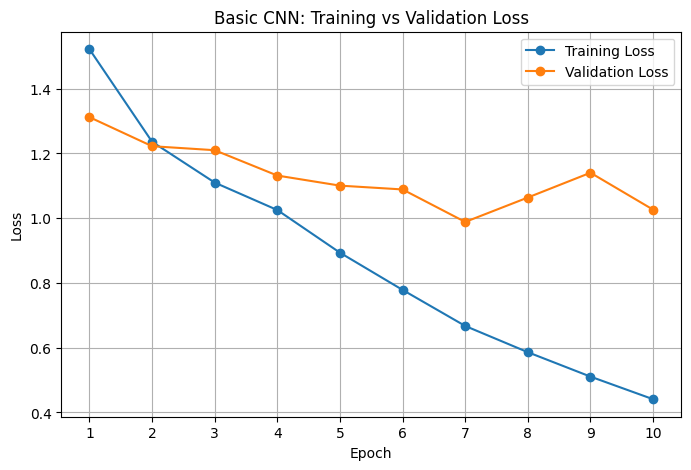

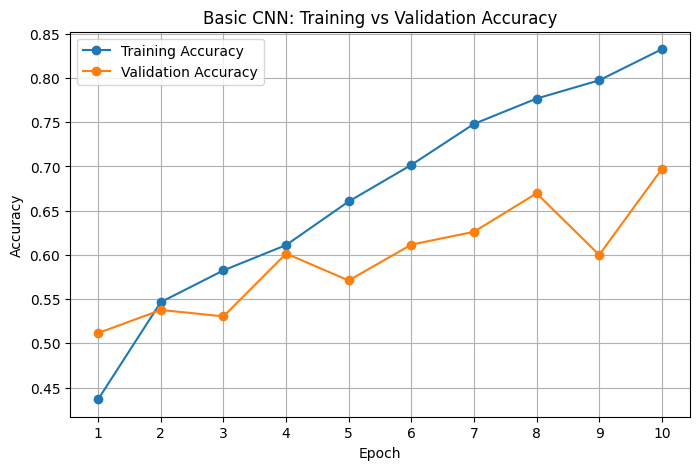

Both Graphs Saved Successfully!


In [ ]:

import matplotlib.pyplot as plt
import os

epochs = range(1, len(history_basic["train_loss"]) + 1)

# Create folder for saving graphs
save_folder = "/content/drive/MyDrive/CVPR_Project"
os.makedirs(save_folder, exist_ok=True)

# -----------------------------
# Graph 1: Training vs Validation Loss
# -----------------------------

plt.figure(figsize=(8, 5))

plt.plot(epochs, history_basic["train_loss"],
         marker='o', label='Training Loss')

plt.plot(epochs, history_basic["val_loss"],
         marker='o', label='Validation Loss')

plt.title("Basic CNN: Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(save_folder, "basic_cnn_loss.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# -----------------------------
# Graph 2: Training vs Validation Accuracy
# -----------------------------

plt.figure(figsize=(8, 5))

plt.plot(epochs, history_basic["train_acc"],
         marker='o', label='Training Accuracy')

plt.plot(epochs, history_basic["val_acc"],
         marker='o', label='Validation Accuracy')

plt.title("Basic CNN: Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(save_folder, "basic_cnn_accuracy.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Both Graphs Saved Successfully!")


In [ ]:
print("BASIC CNN PERFORMANCE REPORT")
print("=" * 65)

for i in range(len(history_basic["train_loss"])):
    print(
        f"Epoch {i+1:02d} | "
        f"Train Loss: {history_basic['train_loss'][i]:.4f} | "
        f"Val Loss: {history_basic['val_loss'][i]:.4f} | "
        f"Train Acc: {history_basic['train_acc'][i]*100:.2f}% | "
        f"Val Acc: {history_basic['val_acc'][i]*100:.2f}%"
    )

best_epoch = history_basic["val_acc"].index(
    max(history_basic["val_acc"])
) + 1

print("=" * 65)
print("Best Validation Accuracy:",
      f"{max(history_basic['val_acc'])*100:.2f}%")
print("Best Epoch:", best_epoch)
print("Lowest Validation Loss:",
      f"{min(history_basic['val_loss']):.4f}")

BASIC CNN PERFORMANCE REPORT
Epoch 01 | Train Loss: 1.5217 | Val Loss: 1.3119 | Train Acc: 43.68% | Val Acc: 51.16%
Epoch 02 | Train Loss: 1.2359 | Val Loss: 1.2222 | Train Acc: 54.66% | Val Acc: 53.77%
Epoch 03 | Train Loss: 1.1098 | Val Loss: 1.2098 | Train Acc: 58.25% | Val Acc: 53.04%
Epoch 04 | Train Loss: 1.0250 | Val Loss: 1.1315 | Train Acc: 61.11% | Val Acc: 60.14%
Epoch 05 | Train Loss: 0.8933 | Val Loss: 1.1004 | Train Acc: 66.04% | Val Acc: 57.10%
Epoch 06 | Train Loss: 0.7784 | Val Loss: 1.0886 | Train Acc: 70.17% | Val Acc: 61.16%
Epoch 07 | Train Loss: 0.6670 | Val Loss: 0.9883 | Train Acc: 74.81% | Val Acc: 62.61%
Epoch 08 | Train Loss: 0.5859 | Val Loss: 1.0637 | Train Acc: 77.67% | Val Acc: 66.96%
Epoch 09 | Train Loss: 0.5106 | Val Loss: 1.1402 | Train Acc: 79.74% | Val Acc: 60.00%
Epoch 10 | Train Loss: 0.4407 | Val Loss: 1.0262 | Train Acc: 83.25% | Val Acc: 69.71%
Best Validation Accuracy: 69.71%
Best Epoch: 10
Lowest Validation Loss: 0.9883


In [ ]:

# Create a fresh CNN model for the augmentation experiment

model_aug = SimpleCNN(
    num_classes=len(class_to_idx),
    p_dropout=0.0
).to(device)

print("Augmented CNN Model Created Successfully!")

print("Device:", device)

print(
    "Trainable Parameters:",
    sum(p.numel() for p in model_aug.parameters()
        if p.requires_grad)
)


Augmented CNN Model Created Successfully!
Device: cuda
Trainable Parameters: 2121767


In [ ]:

history_aug = train_model(
    model_aug,
    train_loader_aug,
    val_loader_clean,
    epochs=10,
    lr=0.001
)

print("\nAugmented CNN Training Completed!")


Epoch [1/10] | Train Loss: 1.5295 | Train Accuracy: 42.81% | Val Loss: 1.3021 | Val Accuracy: 51.30%
Epoch [2/10] | Train Loss: 1.2255 | Train Accuracy: 55.49% | Val Loss: 1.1023 | Val Accuracy: 60.58%
Epoch [3/10] | Train Loss: 1.0681 | Train Accuracy: 60.82% | Val Loss: 0.9886 | Val Accuracy: 65.07%
Epoch [4/10] | Train Loss: 0.9573 | Train Accuracy: 63.25% | Val Loss: 0.9198 | Val Accuracy: 64.20%
Epoch [5/10] | Train Loss: 0.9047 | Train Accuracy: 65.68% | Val Loss: 1.0513 | Val Accuracy: 59.86%
Epoch [6/10] | Train Loss: 0.8647 | Train Accuracy: 66.73% | Val Loss: 0.9001 | Val Accuracy: 66.09%
Epoch [7/10] | Train Loss: 0.8148 | Train Accuracy: 68.43% | Val Loss: 0.8286 | Val Accuracy: 67.25%
Epoch [8/10] | Train Loss: 0.7941 | Train Accuracy: 69.23% | Val Loss: 0.8698 | Val Accuracy: 64.93%
Epoch [9/10] | Train Loss: 0.7615 | Train Accuracy: 71.40% | Val Loss: 0.8275 | Val Accuracy: 68.99%
Epoch [10/10] | Train Loss: 0.7277 | Train Accuracy: 72.53% | Val Loss: 0.8248 | Val Accura

In [ ]:

torch.save({
    "model_state_dict": model_aug.state_dict(),
    "class_to_idx": class_to_idx,
    "img_size": IMG_SIZE
}, "/content/drive/MyDrive/CVPR_Project/augmented_cnn.pth")

print("Augmented CNN Model Saved Successfully!")


Augmented CNN Model Saved Successfully!


In [ ]:
print("AUGMENTED CNN PERFORMANCE REPORT")
print("=" * 65)

for i in range(len(history_aug["train_loss"])):
    print(
        f"Epoch {i+1:02d} | "
        f"Train Loss: {history_aug['train_loss'][i]:.4f} | "
        f"Val Loss: {history_aug['val_loss'][i]:.4f} | "
        f"Train Acc: {history_aug['train_acc'][i]*100:.2f}% | "
        f"Val Acc: {history_aug['val_acc'][i]*100:.2f}%"
    )

best_epoch_aug = history_aug["val_acc"].index(
    max(history_aug["val_acc"])
) + 1

print("=" * 65)
print("Best Validation Accuracy:",
      f"{max(history_aug['val_acc'])*100:.2f}%")
print("Best Epoch:", best_epoch_aug)
print("Lowest Validation Loss:",
      f"{min(history_aug['val_loss']):.4f}")

AUGMENTED CNN PERFORMANCE REPORT
Epoch 01 | Train Loss: 1.5295 | Val Loss: 1.3021 | Train Acc: 42.81% | Val Acc: 51.30%
Epoch 02 | Train Loss: 1.2255 | Val Loss: 1.1023 | Train Acc: 55.49% | Val Acc: 60.58%
Epoch 03 | Train Loss: 1.0681 | Val Loss: 0.9886 | Train Acc: 60.82% | Val Acc: 65.07%
Epoch 04 | Train Loss: 0.9573 | Val Loss: 0.9198 | Train Acc: 63.25% | Val Acc: 64.20%
Epoch 05 | Train Loss: 0.9047 | Val Loss: 1.0513 | Train Acc: 65.68% | Val Acc: 59.86%
Epoch 06 | Train Loss: 0.8647 | Val Loss: 0.9001 | Train Acc: 66.73% | Val Acc: 66.09%
Epoch 07 | Train Loss: 0.8148 | Val Loss: 0.8286 | Train Acc: 68.43% | Val Acc: 67.25%
Epoch 08 | Train Loss: 0.7941 | Val Loss: 0.8698 | Train Acc: 69.23% | Val Acc: 64.93%
Epoch 09 | Train Loss: 0.7615 | Val Loss: 0.8275 | Train Acc: 71.40% | Val Acc: 68.99%
Epoch 10 | Train Loss: 0.7277 | Val Loss: 0.8248 | Train Acc: 72.53% | Val Acc: 67.68%
Best Validation Accuracy: 68.99%
Best Epoch: 9
Lowest Validation Loss: 0.8248


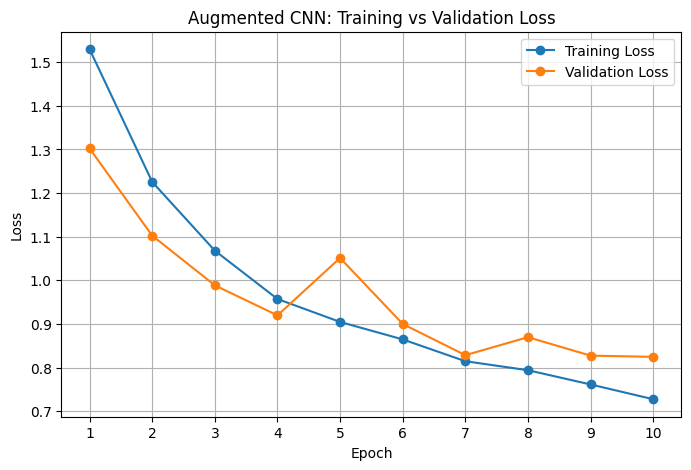

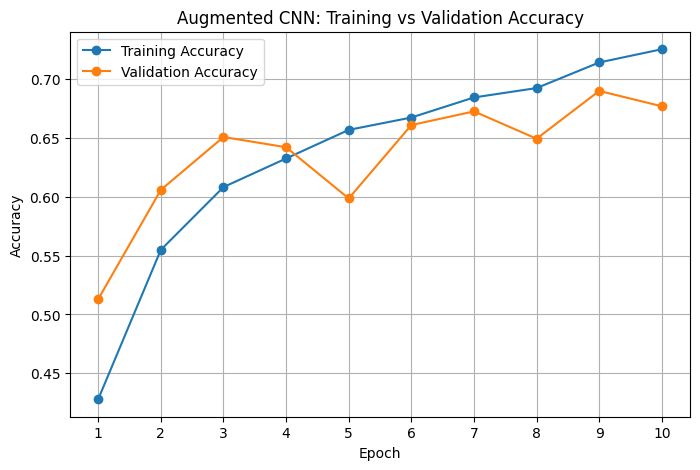

Augmented CNN Graphs Saved Successfully!


In [ ]:

import matplotlib.pyplot as plt
import os

epochs = range(1, len(history_aug["train_loss"]) + 1)

save_folder = "/content/drive/MyDrive/CVPR_Project"
os.makedirs(save_folder, exist_ok=True)

# Graph 1: Augmented CNN Loss

plt.figure(figsize=(8, 5))

plt.plot(epochs, history_aug["train_loss"],
         marker='o', label='Training Loss')

plt.plot(epochs, history_aug["val_loss"],
         marker='o', label='Validation Loss')

plt.title("Augmented CNN: Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(save_folder, "augmented_cnn_loss.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Graph 2: Augmented CNN Accuracy

plt.figure(figsize=(8, 5))

plt.plot(epochs, history_aug["train_acc"],
         marker='o', label='Training Accuracy')

plt.plot(epochs, history_aug["val_acc"],
         marker='o', label='Validation Accuracy')

plt.title("Augmented CNN: Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(save_folder, "augmented_cnn_accuracy.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Augmented CNN Graphs Saved Successfully!")





Basic CNN CLASSIFICATION REPORT
                                   precision    recall  f1-score   support

marigold - Alternaria Leaf Blight       0.92      0.90      0.91        68
        marigold - Helathy Leaves       0.91      0.93      0.92        55
          marigold - Pest Damaged       0.75      0.80      0.77        15
                   rose - Healthy       0.69      0.90      0.78       233
               rose - Pest Damage       0.74      0.69      0.71       158
         rose - Rose Mosaic Virus       0.38      0.41      0.40        49
           rose - botrytis blight       0.40      0.17      0.24       112

                         accuracy                           0.70       690
                        macro avg       0.68      0.68      0.68       690
                     weighted avg       0.67      0.70      0.67       690



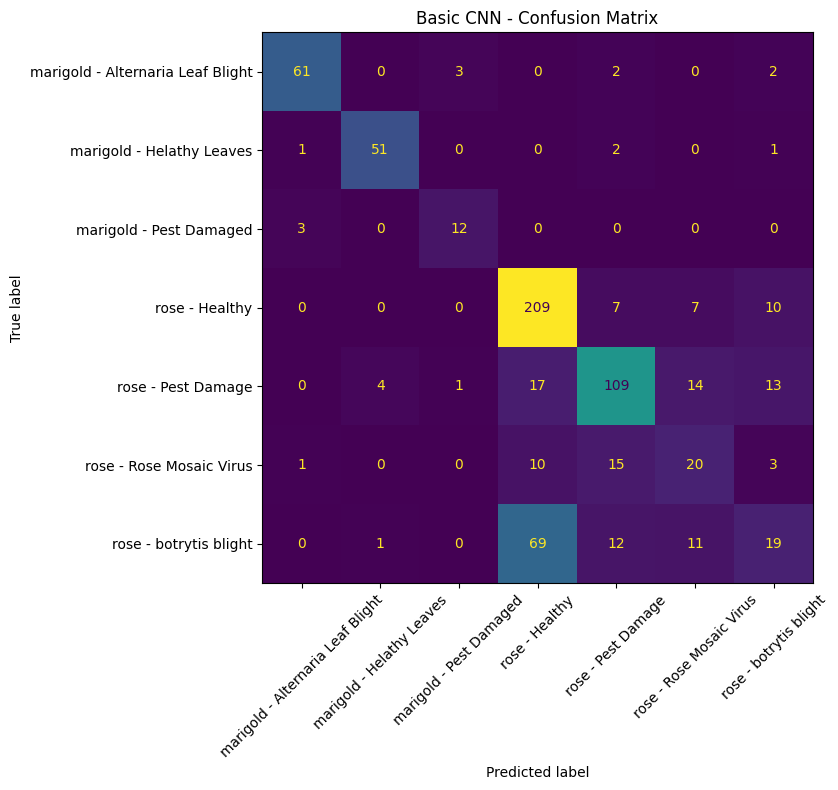


Augmented CNN CLASSIFICATION REPORT
                                   precision    recall  f1-score   support

marigold - Alternaria Leaf Blight       0.79      0.90      0.84        68
        marigold - Helathy Leaves       0.82      0.96      0.88        55
          marigold - Pest Damaged       1.00      0.27      0.42        15
                   rose - Healthy       0.64      0.96      0.77       233
               rose - Pest Damage       0.76      0.71      0.73       158
         rose - Rose Mosaic Virus       0.53      0.18      0.27        49
           rose - botrytis blight       0.15      0.04      0.06       112

                         accuracy                           0.68       690
                        macro avg       0.67      0.57      0.57       690
                     weighted avg       0.61      0.68      0.62       690



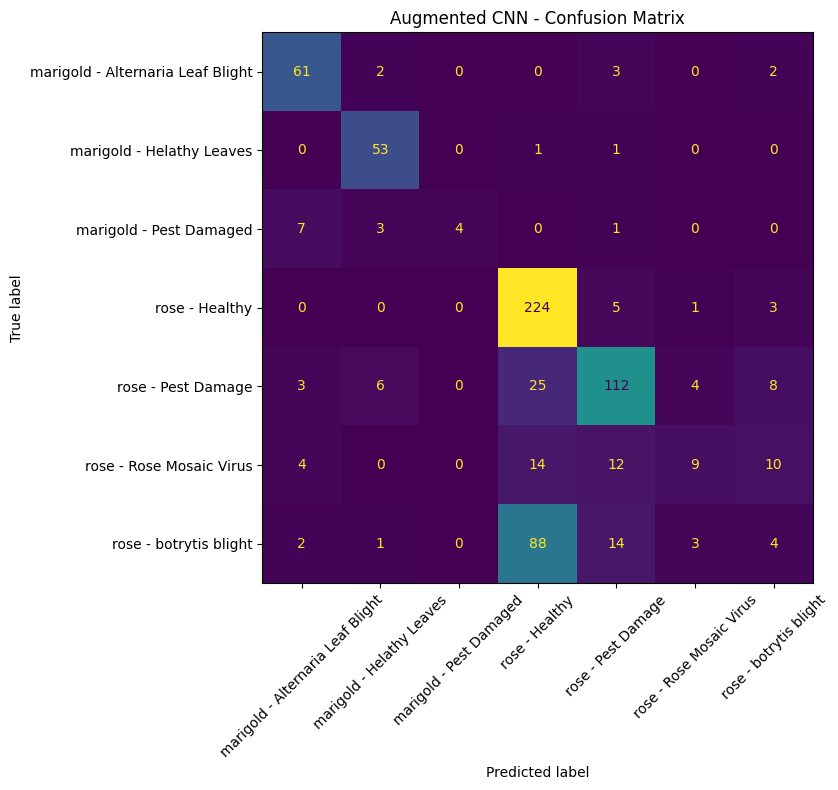

In [ ]:

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Class names in correct numerical order
idx_to_class = {
    value: key for key, value in class_to_idx.items()
}

class_labels = [
    idx_to_class[i] for i in range(len(idx_to_class))
]

def evaluate_model(model, model_name):

    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():

        for images, labels in val_loader_clean:

            images = images.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            y_true.extend(labels.numpy())
            y_pred.extend(predictions.cpu().numpy())

    print("\n", "=" * 60)
    print(model_name, "CLASSIFICATION REPORT")
    print("=" * 60)

    print(classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_labels))),
        target_names=class_labels,
        zero_division=0
    ))

    # Confusion Matrix
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=list(range(len(class_labels)))
    )

    plt.figure(figsize=(10, 8))

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_labels
    )

    display.plot(
        ax=plt.gca(),
        xticks_rotation=45,
        colorbar=False,
        values_format='d'
    )

    plt.title(model_name + " - Confusion Matrix")
    plt.tight_layout()

    file_name = model_name.lower().replace(" ", "_")
    plt.savefig(
        f"/content/drive/MyDrive/CVPR_Project/{file_name}_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    return y_true, y_pred


# Evaluate Basic CNN
basic_results = evaluate_model(
    model_basic,
    "Basic CNN"
)

# Evaluate Augmented CNN
aug_results = evaluate_model(
    model_aug,
    "Augmented CNN"
)


In [ ]:

class FilterCNN(nn.Module):

    def __init__(self, num_classes=7):
        super(FilterCNN, self).__init__()

        # Convolution Layers with fewer filters
        self.conv1 = nn.Conv2d(3, 8, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(16, 32, kernel_size=3, padding=1)

        # Max Pooling
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Fully Connected Layers
        self.fc1 = nn.Linear(32 * 16 * 16, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x


print("FilterCNN Architecture Defined Successfully!")


FilterCNN Architecture Defined Successfully!


In [ ]:

model_filter = FilterCNN(
    num_classes=len(class_to_idx)
).to(device)

total_params_filter = sum(
    p.numel() for p in model_filter.parameters()
    if p.requires_grad
)

print("Filter CNN Model Created Successfully!")
print("Device:", device)
print("Trainable Parameters:", total_params_filter)


Filter CNN Model Created Successfully!
Device: cuda
Trainable Parameters: 1055639


In [ ]:

history_filter = train_model(
    model_filter,
    train_loader_basic,
    val_loader_clean,
    epochs=10,
    lr=0.001
)

print("\nFilter CNN Training Completed!")


Epoch [1/10] | Train Loss: 1.5458 | Train Accuracy: 42.52% | Val Loss: 1.3247 | Val Accuracy: 53.33%
Epoch [2/10] | Train Loss: 1.2358 | Train Accuracy: 54.30% | Val Loss: 1.1532 | Val Accuracy: 57.54%
Epoch [3/10] | Train Loss: 1.0764 | Train Accuracy: 59.77% | Val Loss: 1.0766 | Val Accuracy: 59.42%
Epoch [4/10] | Train Loss: 0.9774 | Train Accuracy: 64.12% | Val Loss: 1.0459 | Val Accuracy: 60.43%
Epoch [5/10] | Train Loss: 0.8762 | Train Accuracy: 66.22% | Val Loss: 0.9613 | Val Accuracy: 62.90%
Epoch [6/10] | Train Loss: 0.7808 | Train Accuracy: 71.04% | Val Loss: 0.9699 | Val Accuracy: 64.49%
Epoch [7/10] | Train Loss: 0.7040 | Train Accuracy: 73.58% | Val Loss: 1.0648 | Val Accuracy: 60.43%
Epoch [8/10] | Train Loss: 0.6316 | Train Accuracy: 74.99% | Val Loss: 1.0986 | Val Accuracy: 61.45%
Epoch [9/10] | Train Loss: 0.6089 | Train Accuracy: 76.55% | Val Loss: 1.0531 | Val Accuracy: 62.90%
Epoch [10/10] | Train Loss: 0.5397 | Train Accuracy: 79.52% | Val Loss: 0.9818 | Val Accura

In [ ]:

torch.save({
    "model_state_dict": model_filter.state_dict(),
    "class_to_idx": class_to_idx,
    "img_size": IMG_SIZE
}, "/content/drive/MyDrive/CVPR_Project/filter_cnn.pth")

print("Filter CNN Model Saved Successfully!")


Filter CNN Model Saved Successfully!


In [ ]:

print("FILTER CNN PERFORMANCE REPORT")
print("=" * 65)

for i in range(len(history_filter["train_loss"])):
    print(
        f"Epoch {i+1:02d} | "
        f"Train Loss: {history_filter['train_loss'][i]:.4f} | "
        f"Val Loss: {history_filter['val_loss'][i]:.4f} | "
        f"Train Acc: {history_filter['train_acc'][i]*100:.2f}% | "
        f"Val Acc: {history_filter['val_acc'][i]*100:.2f}%"
    )

best_epoch_filter = history_filter["val_acc"].index(
    max(history_filter["val_acc"])
) + 1

print("=" * 65)
print("Completed Epochs:", len(history_filter["train_loss"]))
print("Best Validation Accuracy:",
      f"{max(history_filter['val_acc'])*100:.2f}%")
print("Best Epoch:", best_epoch_filter)
print("Lowest Validation Loss:",
      f"{min(history_filter['val_loss']):.4f}")


FILTER CNN PERFORMANCE REPORT
Epoch 01 | Train Loss: 1.5458 | Val Loss: 1.3247 | Train Acc: 42.52% | Val Acc: 53.33%
Epoch 02 | Train Loss: 1.2358 | Val Loss: 1.1532 | Train Acc: 54.30% | Val Acc: 57.54%
Epoch 03 | Train Loss: 1.0764 | Val Loss: 1.0766 | Train Acc: 59.77% | Val Acc: 59.42%
Epoch 04 | Train Loss: 0.9774 | Val Loss: 1.0459 | Train Acc: 64.12% | Val Acc: 60.43%
Epoch 05 | Train Loss: 0.8762 | Val Loss: 0.9613 | Train Acc: 66.22% | Val Acc: 62.90%
Epoch 06 | Train Loss: 0.7808 | Val Loss: 0.9699 | Train Acc: 71.04% | Val Acc: 64.49%
Epoch 07 | Train Loss: 0.7040 | Val Loss: 1.0648 | Train Acc: 73.58% | Val Acc: 60.43%
Epoch 08 | Train Loss: 0.6316 | Val Loss: 1.0986 | Train Acc: 74.99% | Val Acc: 61.45%
Epoch 09 | Train Loss: 0.6089 | Val Loss: 1.0531 | Train Acc: 76.55% | Val Acc: 62.90%
Epoch 10 | Train Loss: 0.5397 | Val Loss: 0.9818 | Train Acc: 79.52% | Val Acc: 65.36%
Completed Epochs: 10
Best Validation Accuracy: 65.36%
Best Epoch: 10
Lowest Validation Loss: 0.9613


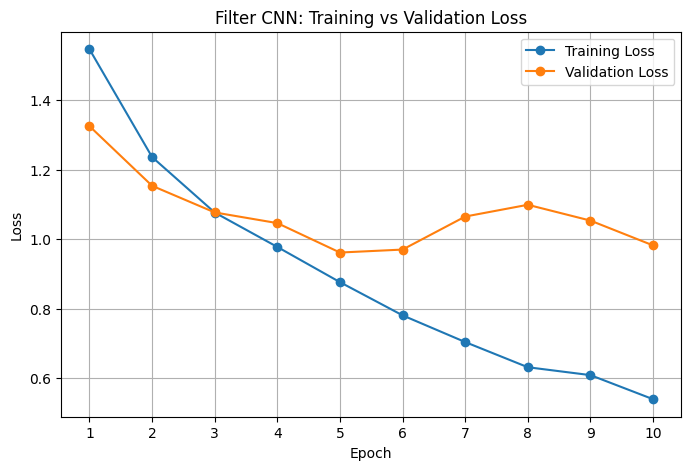

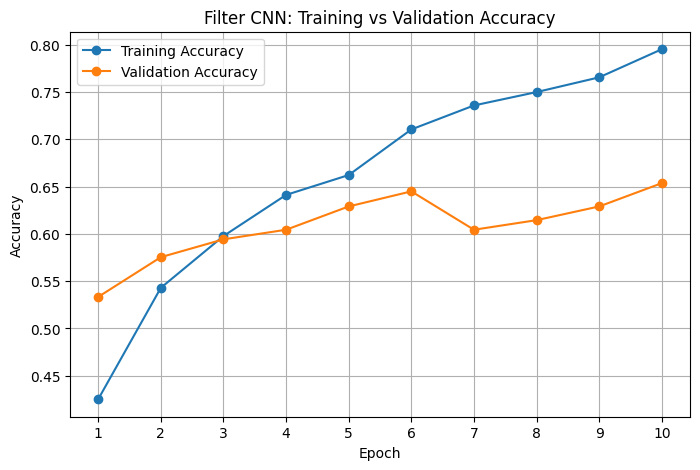

Filter CNN Graphs Saved Successfully!


In [ ]:

import matplotlib.pyplot as plt
import os

epochs = range(1, len(history_filter["train_loss"]) + 1)

save_folder = "/content/drive/MyDrive/CVPR_Project"
os.makedirs(save_folder, exist_ok=True)

# Graph 1: Loss

plt.figure(figsize=(8, 5))

plt.plot(epochs, history_filter["train_loss"],
         marker='o', label='Training Loss')

plt.plot(epochs, history_filter["val_loss"],
         marker='o', label='Validation Loss')

plt.title("Filter CNN: Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(save_folder, "filter_cnn_loss.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Graph 2: Accuracy

plt.figure(figsize=(8, 5))

plt.plot(epochs, history_filter["train_acc"],
         marker='o', label='Training Accuracy')

plt.plot(epochs, history_filter["val_acc"],
         marker='o', label='Validation Accuracy')

plt.title("Filter CNN: Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(save_folder, "filter_cnn_accuracy.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Filter CNN Graphs Saved Successfully!")



Filter CNN CLASSIFICATION REPORT
                                   precision    recall  f1-score   support

marigold - Alternaria Leaf Blight       0.85      0.90      0.87        68
        marigold - Helathy Leaves       0.82      0.93      0.87        55
          marigold - Pest Damaged       0.50      0.60      0.55        15
                   rose - Healthy       0.66      0.82      0.73       233
               rose - Pest Damage       0.76      0.61      0.68       158
         rose - Rose Mosaic Virus       0.53      0.33      0.41        49
           rose - botrytis blight       0.29      0.23      0.26       112

                         accuracy                           0.65       690
                        macro avg       0.63      0.63      0.62       690
                     weighted avg       0.64      0.65      0.64       690



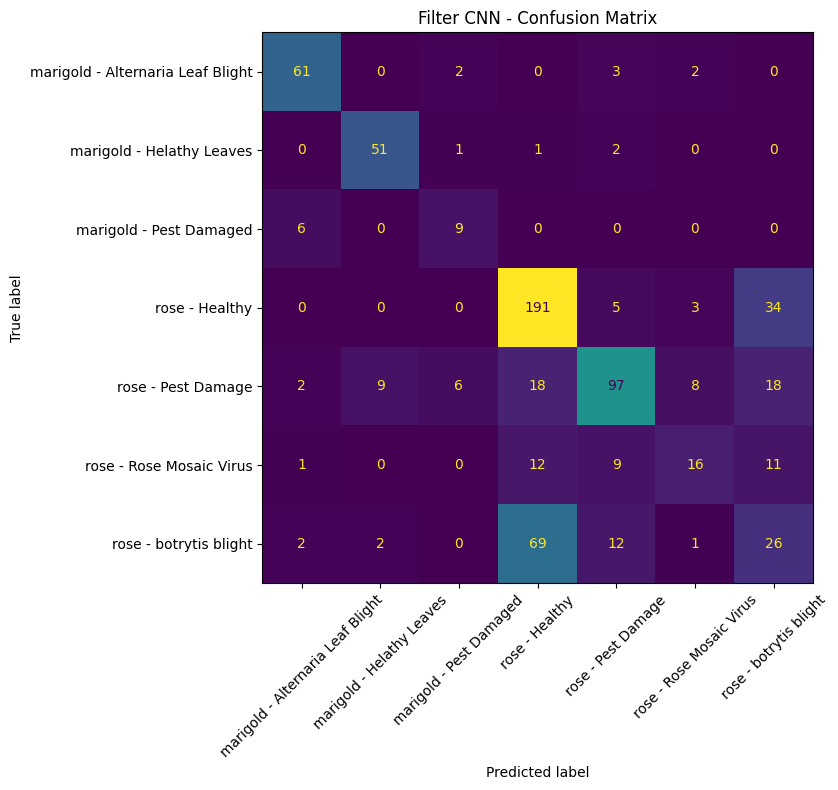

In [ ]:
filter_results = evaluate_model(model_filter, "Filter CNN")

In [ ]:
import pandas as pd
import os
from sklearn.metrics import classification_report

# Three classification reports
report_basic = classification_report(
    basic_results[0], basic_results[1],
    output_dict=True, zero_division=0
)

report_aug = classification_report(
    aug_results[0], aug_results[1],
    output_dict=True, zero_division=0
)

report_filter = classification_report(
    filter_results[0], filter_results[1],
    output_dict=True, zero_division=0
)

# Function to collect model results
def collect_results(name, model, history, report):

    parameters = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    return {
        "Model": name,
        "Parameters": parameters,
        "Train Accuracy (%)": round(history["train_acc"][-1] * 100, 2),
        "Final Val Accuracy (%)": round(history["val_acc"][-1] * 100, 2),
        "Best Val Accuracy (%)": round(max(history["val_acc"]) * 100, 2),
        "Lowest Val Loss": round(min(history["val_loss"]), 4),
        "Macro F1": round(report["macro avg"]["f1-score"], 2),
        "Weighted F1": round(report["weighted avg"]["f1-score"], 2)
    }

# Create comparison table
comparison = pd.DataFrame([
    collect_results("Basic CNN", model_basic, history_basic, report_basic),
    collect_results("Augmented CNN", model_aug, history_aug, report_aug),
    collect_results("Filter CNN", model_filter, history_filter, report_filter)
])

# Display results
display(comparison)

# Save comparison as CSV
save_folder = "/content/drive/MyDrive/CVPR_Project"

comparison.to_csv(
    os.path.join(save_folder, "final_model_comparison.csv"),
    index=False
)

print("Final comparison saved successfully!")

,Model,Parameters,Train Accuracy (%),Final Val Accuracy (%),Best Val Accuracy (%),Lowest Val Loss,Macro F1,Weighted F1
0,Basic CNN,2121767,83.25,69.71,69.71,0.9883,0.68,0.67
1,Augmented CNN,2121767,72.53,67.68,68.99,0.8248,0.57,0.62
2,Filter CNN,1055639,79.52,65.36,65.36,0.9613,0.62,0.64


Final comparison saved successfully!


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/Rose_Marigold_Dataset/Perfect Data Set"

print("CLASS-WISE IMAGE COUNT")
print("-" * 45)

for class_name in sorted(os.listdir(dataset_path)):

    class_path = os.path.join(dataset_path, class_name)

    if os.path.isdir(class_path):
        count = sum(
            1
            for root, dirs, files in os.walk(class_path)
            for file in files
            if file.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
        )

        print(f"{class_name}: {count}")

CLASS-WISE IMAGE COUNT
---------------------------------------------
marigold: 689
rose: 2760


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/Rose_Marigold_Dataset/Perfect Data Set"

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

print("SEVEN CLASS-WISE IMAGE COUNT")
print("=" * 55)

grand_total = 0

for plant in sorted(os.listdir(dataset_path)):

    plant_path = os.path.join(dataset_path, plant)

    if not os.path.isdir(plant_path):
        continue

    for class_name in sorted(os.listdir(plant_path)):

        class_path = os.path.join(plant_path, class_name)

        if not os.path.isdir(class_path):
            continue

        count = sum(
            1
            for root, dirs, files in os.walk(class_path)
            for file in files
            if file.lower().endswith(image_extensions)
        )

        grand_total += count

        print(f"{plant} - {class_name}: {count}")

print("=" * 55)
print("TOTAL IMAGES:", grand_total)

SEVEN CLASS-WISE IMAGE COUNT
marigold - Alternaria Leaf Blight: 338
marigold - Helathy Leaves: 273
marigold - Pest Damaged: 78
rose - Healthy: 1167
rose - Pest Damage: 790
rose - Rose Mosaic Virus: 245
rose - botrytis blight: 558
TOTAL IMAGES: 3449


In [ ]:
import pandas as pd
import os

# Store all three models and their histories
models_data = {
    "Basic CNN": history_basic,
    "Augmented CNN": history_aug,
    "Filter CNN": history_filter
}

overfitting_results = []

for model_name, history in models_data.items():

    # Final epoch accuracy
    train_acc = history["train_acc"][-1] * 100
    val_acc = history["val_acc"][-1] * 100

    # Accuracy gap
    accuracy_gap = train_acc - val_acc

    # Final epoch loss
    train_loss = history["train_loss"][-1]
    val_loss = history["val_loss"][-1]

    # Loss gap
    loss_gap = val_loss - train_loss

    # Best validation accuracy and its epoch
    best_val_acc = max(history["val_acc"]) * 100
    best_epoch = history["val_acc"].index(
        max(history["val_acc"])
    ) + 1

    overfitting_results.append({
        "Model": model_name,
        "Training Accuracy (%)": round(train_acc, 2),
        "Validation Accuracy (%)": round(val_acc, 2),
        "Accuracy Gap (%)": round(accuracy_gap, 2),
        "Final Training Loss": round(train_loss, 4),
        "Final Validation Loss": round(val_loss, 4),
        "Loss Gap": round(loss_gap, 4),
        "Best Validation Accuracy (%)": round(best_val_acc, 2),
        "Best Epoch": best_epoch
    })

# Create and display table
overfitting_df = pd.DataFrame(overfitting_results)

display(overfitting_df)

# Save results
save_folder = "/content/drive/MyDrive/CVPR_Project"

overfitting_df.to_csv(
    os.path.join(save_folder, "overfitting_analysis.csv"),
    index=False
)

print("Overfitting Analysis saved successfully!")

,Model,Training Accuracy (%),Validation Accuracy (%),Accuracy Gap (%),Final Training Loss,Final Validation Loss,Loss Gap,Best Validation Accuracy (%),Best Epoch
0,Basic CNN,83.25,69.71,13.54,0.4407,1.0262,0.5855,69.71,10
1,Augmented CNN,72.53,67.68,4.85,0.7277,0.8248,0.0971,68.99,9
2,Filter CNN,79.52,65.36,14.16,0.5397,0.9818,0.4421,65.36,10


Overfitting Analysis saved successfully!


In [ ]:
# Print model architectures and parameter counts

for name, model in [
    ("Basic CNN", model_basic),
    ("Augmented CNN", model_aug),
    ("Filter CNN", model_filter)
]:

    total_params = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)
    print(model)
    print("Trainable Parameters:", total_params)


Basic CNN
SimpleCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.0, inplace=False)
  (fc1): Linear(in_features=16384, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=7, bias=True)
)
Trainable Parameters: 2121767

Augmented CNN
SimpleCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.0, inplace=False)
  (fc1): Linear(in_features=16384, out_features=128, bias=True)
  (fc2): Linear(

In [ ]:
import os

save_folder = "/content/drive/MyDrive/CVPR_Project"

# Expected project files
expected_files = [
    "basic_cnn.pth",
    "augmented_cnn.pth",
    "filter_cnn.pth",

    "basic_cnn_loss.png",
    "basic_cnn_accuracy.png",
    "augmented_cnn_loss.png",
    "augmented_cnn_accuracy.png",
    "filter_cnn_loss.png",
    "filter_cnn_accuracy.png",

    "basic_cnn_confusion_matrix.png",
    "augmented_cnn_confusion_matrix.png",
    "filter_cnn_confusion_matrix.png",

    "final_model_comparison.csv",
    "overfitting_analysis.csv"
]

print("=" * 60)
print("CVPR PROJECT FILE VERIFICATION")
print("=" * 60)

missing_files = []

for file_name in expected_files:

    file_path = os.path.join(save_folder, file_name)

    if os.path.exists(file_path):
        size_kb = os.path.getsize(file_path) / 1024
        print(f"[OK] {file_name} ({size_kb:.2f} KB)")
    else:
        print(f"[MISSING] {file_name}")
        missing_files.append(file_name)

print("=" * 60)
print("Total Expected Files:", len(expected_files))
print("Available Files:", len(expected_files) - len(missing_files))
print("Missing Files:", len(missing_files))

if not missing_files:
    print("\nAll expected project files are saved successfully!")
else:
    print("\nPlease check the missing files.")

CVPR PROJECT FILE VERIFICATION
[OK] basic_cnn.pth (8292.60 KB)
[OK] augmented_cnn.pth (8292.66 KB)
[OK] filter_cnn.pth (4127.93 KB)
[OK] basic_cnn_loss.png (136.91 KB)
[OK] basic_cnn_accuracy.png (159.30 KB)
[OK] augmented_cnn_loss.png (145.20 KB)
[OK] augmented_cnn_accuracy.png (152.08 KB)
[OK] filter_cnn_loss.png (132.75 KB)
[OK] filter_cnn_accuracy.png (147.32 KB)
[OK] basic_cnn_confusion_matrix.png (305.85 KB)
[OK] augmented_cnn_confusion_matrix.png (307.96 KB)
[OK] filter_cnn_confusion_matrix.png (305.72 KB)
[OK] final_model_comparison.csv (0.28 KB)
[OK] overfitting_analysis.csv (0.33 KB)
Total Expected Files: 14
Available Files: 14
Missing Files: 0

All expected project files are saved successfully!
